In [ ]:
""""Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.
Determine the number of clusters using the elbow method.
Dataset link : https://www.kaggle.com/datasets/kyanyoga/sample-sales-data"""

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering

from scipy.cluster.hierarchy import dendrogram, linkage

In [2]:
data = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print(data.head())

print("\nDataset Shape:", data.shape)

print("\nColumns:")
print(data.columns.tolist())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

X = data[features].dropna()

print(X.head())

   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95


In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Feature Scaling Completed")

Feature Scaling Completed


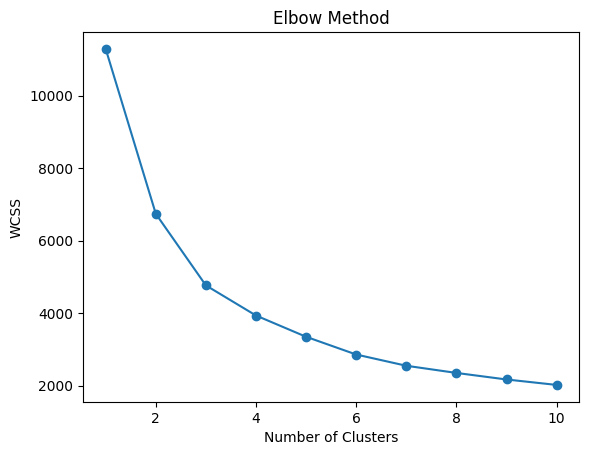

In [5]:
wcss = []

for i in range(1, 11):

    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)


plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters")

plt.ylabel("WCSS")

plt.title("Elbow Method")

plt.show()

In [6]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)

data = data.loc[X.index].copy()

data["KMeans_Cluster"] = kmeans_labels

print(data[["SALES", "KMeans_Cluster"]].head())

print("\nCluster Counts:")

print(data["KMeans_Cluster"].value_counts())

     SALES  KMeans_Cluster
0  2871.00               2
1  2765.90               2
2  3884.34               1
3  3746.70               1
4  5205.27               1

Cluster Counts:
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


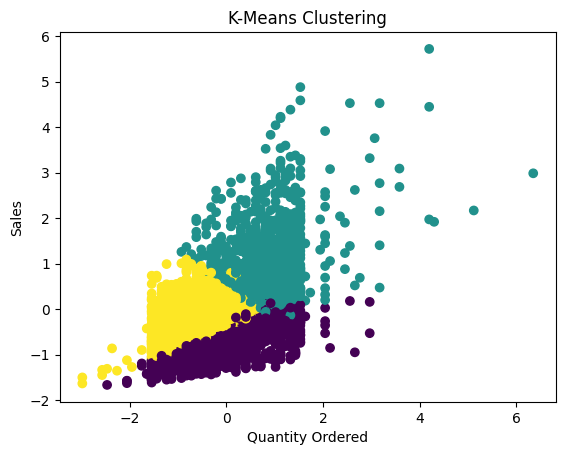

In [9]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 2],
    c=kmeans_labels
)

plt.xlabel("Quantity Ordered")

plt.ylabel("Sales")

plt.title("K-Means Clustering")

plt.show()


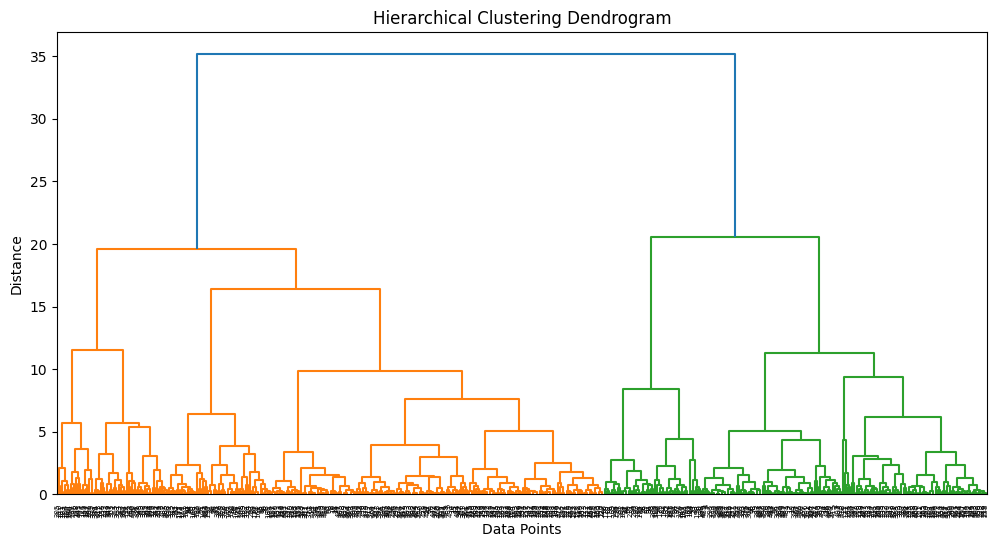

In [10]:
sample_size = min(500, len(X_scaled))

sample = X_scaled[:sample_size]

linked = linkage(sample, method="ward")

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")

plt.xlabel("Data Points")

plt.ylabel("Distance")

plt.show()

In [11]:
hc = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

hc_labels = hc.fit_predict(sample)

print("Hierarchical Cluster Labels:")

print(hc_labels[:20])

Hierarchical Cluster Labels:
[0 0 1 1 1 0 0 1 0 1 0 0 0 0 1 0 0 1 1 1]


In [12]:
print("K-Means Cluster Counts:")

print(pd.Series(kmeans_labels).value_counts())

print("\nHierarchical Cluster Counts:")

print(pd.Series(hc_labels).value_counts())

K-Means Cluster Counts:
2    996
0    975
1    852
Name: count, dtype: int64

Hierarchical Cluster Counts:
0    294
1    153
2     53
Name: count, dtype: int64
